# FIT file exploration

Exploring raw Garmin `.FIT` files (Garmin Instinct Solar) before building the parser and metrics for **supercomp**.

Goals:
- understand the structure of a FIT file
- check data quality (missing heart rate, recording interval)
- calculate heart rate zones and training load (TRIMP) as a first prototype

In [2]:
from pathlib import Path

import fitdecode
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../../data/raw")
fit_files = sorted(DATA_DIR.glob("*.fit"))
fit_files

[PosixPath('../../data/raw/24708813038_ACTIVITY.fit'),
 PosixPath('../../data/raw/24743880919_ACTIVITY.fit'),
 PosixPath('../../data/raw/24743882998_ACTIVITY.fit')]

## 1. Message types

A FIT file is a sequence of messages. `record` messages hold the time series, `session` holds the activity summary.

In [3]:
from collections import Counter

# Which message types are in the file and how many of each?
with fitdecode.FitReader(fit_files[0]) as fit:
    names = Counter(f.name for f in fit if f.frame_type == fitdecode.FIT_FRAME_DATA)
names

Counter({'unknown_233': 2358,
         'record': 623,
         'device_info': 14,
         'unknown_104': 8,
         'time_in_zone': 5,
         'lap': 4,
         'unknown_113': 3,
         'event': 2,
         'file_id': 1,
         'file_creator': 1,
         'unknown_22': 1,
         'unknown_141': 1,
         'device_settings': 1,
         'user_profile': 1,
         'unknown_79': 1,
         'sport': 1,
         'training_settings': 1,
         'zones_target': 1,
         'unknown_140': 1,
         'session': 1,
         'activity': 1})

## 2. Fields in `record` and `session` messages

Location fields (GPS coordinates) are skipped so they don't end up in the notebook output on GitHub.

In [13]:
LOCATION_KEYS = ("position", "lat", "long")


def print_fields(path: Path, message_name: str) -> None:
    """Print all fields of the first message with the given name, excluding location data."""
    with fitdecode.FitReader(path) as fit:
        for frame in fit:
            if frame.frame_type == fitdecode.FIT_FRAME_DATA and frame.name == message_name:
                for field in frame.fields:
                    if any(key in field.name for key in LOCATION_KEYS):
                        continue
                    print(f"{field.name} = {field.value} {field.units or ''}")
                return
    print(f"No '{message_name}' message found")


print_fields(fit_files[0], "record")

timestamp = 2026-10-13 09:33:35+00:00 
distance = 0.71 m
enhanced_speed = 0.0 m/s
enhanced_altitude = 409.20000000000005 m
cycle_length16 = 0.0 m
unknown_88 = 300 
heart_rate = 101 bpm
cadence = 0 rpm
fractional_cadence = 0.0 rpm
unknown_136 = 101 


In [14]:
print_fields(fit_files[0], "session")

timestamp = 2026-10-13 10:12:54+00:00 
start_time = 2026-10-13 09:33:35+00:00 
total_elapsed_time = 2307.116 s
total_timer_time = 2307.116 s
total_distance = 5307.0 m
total_strides = 3084 strides
avg_stroke_count = None strokes/lap
total_work = None J
unknown_78 = None 
sport_profile_name = Laufen 
time_standing = None s
avg_left_power_phase = (None, None, None, None) degrees
avg_left_power_phase_peak = (None, None, None, None) degrees
avg_right_power_phase = (None, None, None, None) degrees
avg_right_power_phase_peak = (None, None, None, None) degrees
enhanced_avg_speed = 2.3 m/s
enhanced_max_speed = 3.34 m/s
unknown_152 = 0 
message_index = 0 
total_calories = 377 kcal
enhanced_avg_speed = None m/s
avg_speed = None m/s
enhanced_max_speed = None m/s
max_speed = None m/s
avg_power = None watts
max_power = None watts
total_ascent = 141 m
total_descent = 212 m
first_lap_index = 0 
num_laps = 4 
num_lengths = None lengths
normalized_power = None watts
training_stress_score = None tss
inte

## 3. Reading a FIT file

Returns per-sample records as a DataFrame plus a session summary. Missing fields return `None` instead of raising an error
(e.g. strength training has no speed or distance).

In [15]:
def read_fit(path: Path) -> tuple[pd.DataFrame, dict]:
    """Read a FIT file and return per-sample records plus session summary."""
    records = []
    session = {}

    with fitdecode.FitReader(path) as fit:
        for frame in fit:
            if frame.frame_type != fitdecode.FIT_FRAME_DATA:
                continue

            # 'record' messages hold the time series (one row per sample)
            if frame.name == "record":
                records.append({
                    "timestamp": frame.get_value("timestamp", fallback=None),
                    "heart_rate": frame.get_value("heart_rate", fallback=None),
                    # Newer devices store speed as 'enhanced_speed'
                    "speed": frame.get_value("enhanced_speed",
                                             fallback=frame.get_value("speed", fallback=None)),
                    "distance": frame.get_value("distance", fallback=None),
                })

            # 'session' message holds the activity summary
            elif frame.name == "session":
                session = {
                    "sport": frame.get_value("sport", fallback=None),
                    "start_time": frame.get_value("start_time", fallback=None),
                    "duration_s": frame.get_value("total_timer_time", fallback=None),
                    "avg_hr": frame.get_value("avg_heart_rate", fallback=None),
                    "max_hr": frame.get_value("max_heart_rate", fallback=None),
                }

    df = pd.DataFrame(records)
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    return df, session


activities = {path.name: read_fit(path) for path in fit_files}

In [7]:
for path in fit_files:
    df, session = read_fit(path)
    print(path.name)
    print("  session:", session)
    print("  samples:", len(df), "| HR missing:", df["heart_rate"].isna().sum())
    # Median gap between samples tells us the recording interval
    print("  median interval (s):", df["timestamp"].diff().dt.total_seconds().median())
    print()

24708813038_ACTIVITY.fit
  session: {'sport': 'running', 'start_time': datetime.datetime(2026, 10, 13, 9, 33, 35, tzinfo=datetime.timezone.utc), 'duration_s': 2307.116, 'avg_hr': 173, 'max_hr': 195}
  samples: 623 | HR missing: 0
  median interval (s): 3.0

24743880919_ACTIVITY.fit
  session: {'sport': 'running', 'start_time': datetime.datetime(2026, 10, 16, 10, 21, 28, tzinfo=datetime.timezone.utc), 'duration_s': 2102.004, 'avg_hr': 174, 'max_hr': 192}
  samples: 508 | HR missing: 0
  median interval (s): 4.0

24743882998_ACTIVITY.fit
  session: {'sport': 'training', 'start_time': datetime.datetime(2026, 10, 16, 11, 14, 29, tzinfo=datetime.timezone.utc), 'duration_s': 999.208, 'avg_hr': 124, 'max_hr': 156}
  samples: 509 | HR missing: 0
  median interval (s): 1.0



## 4. Data quality overview

In [16]:
rows = []
for name, (df, session) in activities.items():
    rows.append({
        "file": name,
        "sport": session.get("sport"),
        "start": session.get("start_time"),
        "duration_min": round((session.get("duration_s") or 0) / 60, 1),
        "avg_hr": session.get("avg_hr"),
        "max_hr": session.get("max_hr"),
        "samples": len(df),
        "hr_missing": int(df["heart_rate"].isna().sum()),
        # Median gap between samples tells us the recording interval
        "median_interval_s": df["timestamp"].diff().dt.total_seconds().median(),
    })

overview = pd.DataFrame(rows)
overview

,file,sport,start,duration_min,avg_hr,max_hr,samples,hr_missing,median_interval_s
0,24708813038_ACTIVITY.fit,running,2026-10-13 09:33:35+00:00,38.5,173,195,623,0,3.0
1,24743880919_ACTIVITY.fit,running,2026-10-16 10:21:28+00:00,35.0,174,192,508,0,4.0
2,24743882998_ACTIVITY.fit,training,2026-10-16 11:14:29+00:00,16.7,124,156,509,0,1.0


**Observations**

- No missing heart rate values in any file.
- Runs were recorded with *smart recording* (median interval 3–4 s), strength training every second.
  → Metrics must use the real time between samples instead of assuming 1 s.
- Highest observed heart rate so far: 195 bpm (used as HR max below).

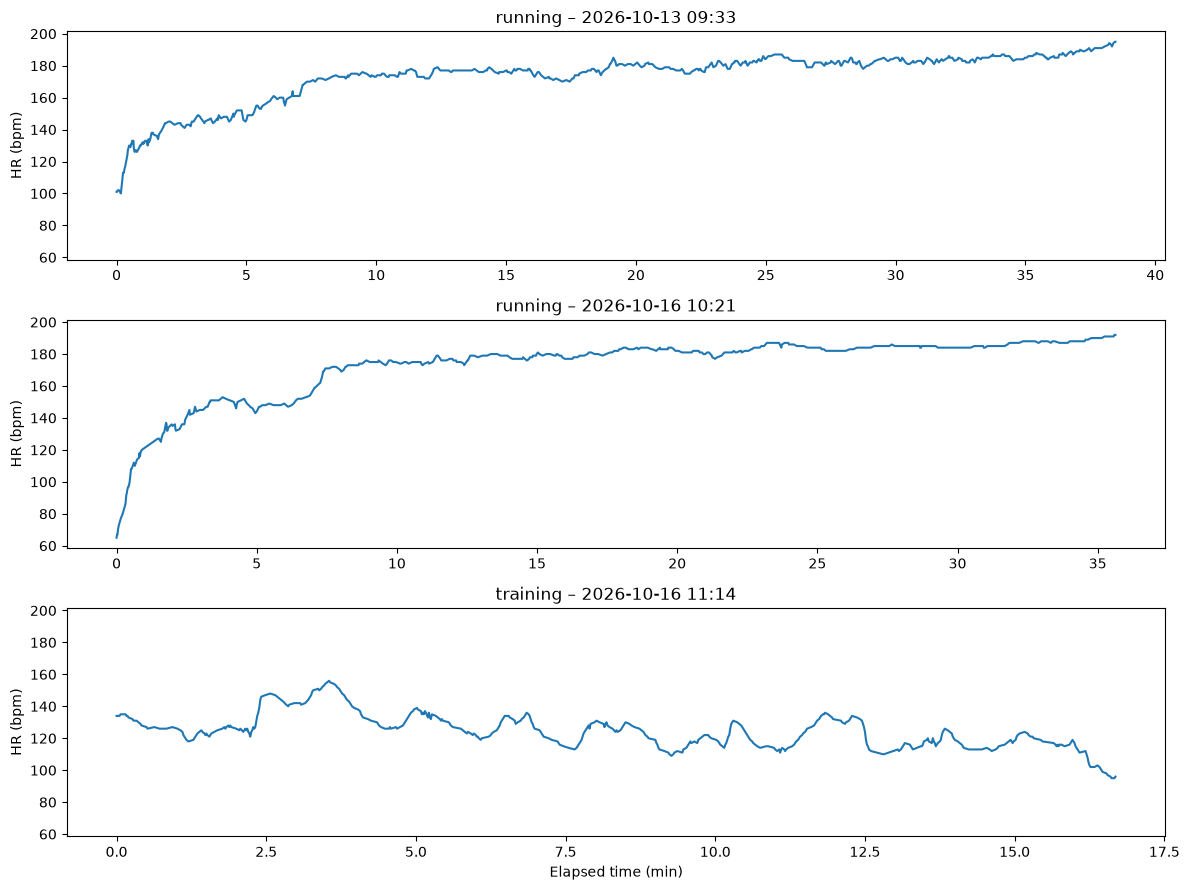

In [17]:
fig, axes = plt.subplots(len(activities), 1, figsize=(12, 3 * len(activities)), sharey=True)
axes = np.atleast_1d(axes)

for ax, (name, (df, session)) in zip(axes, activities.items()):
    elapsed_min = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds() / 60
    ax.plot(elapsed_min, df["heart_rate"])
    ax.set_title(f"{session.get('sport')} – {session.get('start_time'):%Y-%m-%d %H:%M}")
    ax.set_ylabel("HR (bpm)")

axes[-1].set_xlabel("Elapsed time (min)")
plt.tight_layout()
plt.show()

## 5. Athlete parameters

Temporary constants. In the app these will come from the athlete settings.

In [ ]:
HR_REST = 65   # approximate resting HR (Garmin Connect)
HR_MAX = 195   # highest observed value (13 Oct 2026 run)

## 6. Time between samples

Each sample represents the time since the previous one. Gaps are capped so that pauses don't count as training.

In [18]:
def sample_durations(df: pd.DataFrame, max_gap_s: float = 10) -> pd.Series:
    """Seconds represented by each sample, with long gaps (pauses) capped."""
    return df["timestamp"].diff().dt.total_seconds().fillna(0).clip(upper=max_gap_s)

## 7. Heart rate zones (% of heart rate reserve)

Zones based on the Karvonen method: $\%HRR = \frac{HR - HR_{rest}}{HR_{max} - HR_{rest}} \cdot 100$

| Zone | %HRR |
|---|---|
| Z0 | < 50 |
| Z1 | 50–60 |
| Z2 | 60–70 |
| Z3 | 70–80 |
| Z4 | 80–90 |
| Z5 | ≥ 90 |

In [19]:
ZONE_BINS = [-np.inf, 50, 60, 70, 80, 90, np.inf]
ZONE_LABELS = ["Z0", "Z1", "Z2", "Z3", "Z4", "Z5"]


def time_in_zones(df: pd.DataFrame, hr_rest: float, hr_max: float) -> pd.Series:
    """Minutes spent in each heart rate zone."""
    data = df.dropna(subset=["heart_rate"]).copy()
    data["dt"] = sample_durations(data)

    hrr_pct = (data["heart_rate"] - hr_rest) / (hr_max - hr_rest) * 100
    data["zone"] = pd.cut(hrr_pct, bins=ZONE_BINS, labels=ZONE_LABELS, right=False)

    minutes = data.groupby("zone", observed=False)["dt"].sum() / 60
    return minutes.reindex(ZONE_LABELS, fill_value=0)


zones = pd.DataFrame({
    name: time_in_zones(df, HR_REST, HR_MAX) for name, (df, _) in activities.items()
}).T.round(1)
zones

zone,Z0,Z1,Z2,Z3,Z4,Z5
24708813038_ACTIVITY.fit,0.7,1.2,3.7,1.5,17.6,13.7
24743880919_ACTIVITY.fit,1.2,1.0,4.4,0.4,12.1,16.2
24743882998_ACTIVITY.fit,11.9,3.6,1.1,0.0,0.0,0.0


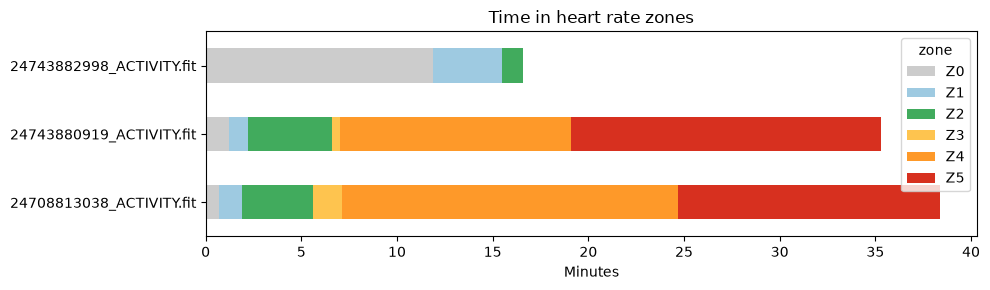

In [20]:
ax = zones.plot(kind="barh", stacked=True, figsize=(10, 3),
                color=["#cccccc", "#9ecae1", "#41ab5d", "#fec44f", "#fe9929", "#d7301f"])
ax.set_xlabel("Minutes")
ax.set_title("Time in heart rate zones")
plt.tight_layout()
plt.show()

## 8. Training load (TRIMP)

**Banister TRIMP**, summed per sample:

$TRIMP = \sum \Delta t_{min} \cdot HRr \cdot a \cdot e^{b \cdot HRr}$, with $HRr = \frac{HR - HR_{rest}}{HR_{max} - HR_{rest}}$

Coefficients: women $a = 0.86,\ b = 1.67$; men $a = 0.64,\ b = 1.92$.

**Edwards TRIMP**: minutes in each zone × zone number (Z1 = 1 … Z5 = 5).

In [23]:
def banister_trimp(df: pd.DataFrame, hr_rest: float, hr_max: float,
                   a: float = 0.86, b: float = 1.67) -> float:
    """Banister TRIMP summed per sample (default coefficients for women)."""
    data = df.dropna(subset=["heart_rate"])
    dt_min = sample_durations(data) / 60
    hrr = ((data["heart_rate"] - hr_rest) / (hr_max - hr_rest)).clip(0, 1)
    return float((dt_min * hrr * a * np.exp(b * hrr)).sum())


def edwards_trimp(zone_minutes: pd.Series) -> float:
    """Edwards TRIMP: minutes in zone weighted by zone number (Z0 counts as 0)."""
    weights = pd.Series(range(len(ZONE_LABELS)), index=ZONE_LABELS)
    return float((zone_minutes * weights).sum())


load = pd.DataFrame([
    {
        "file": name,
        "sport": session.get("sport"),
        "banister_trimp": round(banister_trimp(df, HR_REST, HR_MAX), 1),
        "edwards_trimp": round(edwards_trimp(zones.loc[name]), 1),
    }
    for name, (df, session) in activities.items()
])
load

,file,sport,banister_trimp,edwards_trimp
0,24708813038_ACTIVITY.fit,running,116.0,152.0
1,24743880919_ACTIVITY.fit,running,108.0,140.4
2,24743882998_ACTIVITY.fit,training,14.4,5.8


## 9. Sanity check: per-sample vs. average-HR TRIMP

Calculating TRIMP from the average heart rate should give a similar but slightly lower value,
because the exponential term weights heart rate peaks more than an average does.

In [22]:
def banister_trimp_from_average(session: dict, hr_rest: float, hr_max: float,
                                a: float = 0.86, b: float = 1.67) -> float:
    """Classic Banister TRIMP using session duration and average heart rate."""
    hrr = (session["avg_hr"] - hr_rest) / (hr_max - hr_rest)
    return session["duration_s"] / 60 * hrr * a * np.exp(b * hrr)


load["trimp_from_avg_hr"] = [
    round(banister_trimp_from_average(session, HR_REST, HR_MAX), 1)
    for _, session in activities.values()
]
load

,file,sport,banister_trimp,edwards_trimp,trimp_from_avg_hr
0,24708813038_ACTIVITY.fit,running,116.0,152.0,110.0
1,24743880919_ACTIVITY.fit,running,108.0,140.4,102.5
2,24743882998_ACTIVITY.fit,training,14.4,5.8,13.9


## Findings

- The FIT files are complete (no missing heart rate), but the recording interval differs between activity types.
- Runs are mostly spent in high heart rate zones.
- Per-sample TRIMP is slightly higher than TRIMP from average heart rate, as expected.
- Heart-rate-based TRIMP gives strength training a very low load, although muscular load is high.
  This is a known limitation. Session RPE (sRPE) could complement it.

**Next steps**
- Move `read_fit` to `app/parser/fit.py`
- Move zone and TRIMP functions to `app/metrics/`
- Add unit tests